# Logistic regression in Python

This notebook was generated using AI under general human direction. At the time of generation, the contents have not been comprehensively reviewed by a human analyst.

In this notebook we use logistic regression to predict whether a patient has **heart disease** (`hd`). The steps are:

1. Load the packages and the data
2. Clean the data and add column names
3. Do some quality control on the categorical variables
4. Fit a simple logistic regression that uses only `sex`
5. Fit a logistic regression that uses all of the variables
6. Use the full model to make predictions for new patients

The data come from the UCI Machine Learning Repository (http://archive.ics.uci.edu/ml/index.php), specifically the Cleveland heart disease data set (http://archive.ics.uci.edu/ml/datasets/Heart+Disease).

----

## Load packages

- `pandas` holds the data in a data frame, and `numpy` handles a few numeric operations.
- `matplotlib` draws the graphs.
- `statsmodels` fits the logistic regression using an R-style formula.
- `scipy.stats.chi2` computes the p-value for the pseudo R-squared.

In [20]:
# load-packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

## Load the data

Read `processed_cleveland_data.csv` into a data frame. The file has no header row, so we set `header=None`. The file must be in the same folder as this notebook (or adjust the path). Then look at the first few rows. You'll see the data, but there are no column names yet.

In [21]:
# load-data
df = pd.read_csv("processed_cleveland_data.csv", header=None)

# look at the first few rows
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Clean the data

### Add column names

The columns are described in the UCI documentation (and in `heart-disease_col_names.txt`):

| Column | Description |
|---|---|
| `age` | age in years |
| `sex` | 0 = female, 1 = male |
| `cp` | chest pain: 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic |
| `trestbps` | resting blood pressure (mm Hg) |
| `chol` | serum cholesterol (mg/dl) |
| `fbs` | fasting blood sugar > 120 mg/dl: 1 = true, 0 = false |
| `restecg` | resting ECG: 0 = normal, 1 = ST-T wave abnormality, 2 = probable or definite left ventricular hypertrophy |
| `thalach` | maximum heart rate achieved |
| `exang` | exercise-induced angina: 1 = yes, 0 = no |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | slope of the peak exercise ST segment: 1 = upsloping, 2 = flat, 3 = downsloping |
| `ca` | number of major vessels (0-3) colored by fluoroscopy |
| `thal` | thallium heart scan: 3 = normal, 6 = fixed defect, 7 = reversible defect |
| `hd` | diagnosis of heart disease: 0 = < 50% diameter narrowing, 1-4 = > 50% diameter narrowing |

In [22]:
# add-column-names
df.columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "hd",
]

# now we have data and column names
df.head(3)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,hd
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1


### Check the column types

Check what type each column was read as. The `ca` and `thal` columns contain `"?"` for missing values, so pandas reads them as strings (`object`) and not as numbers.

In [23]:
# check-dtypes
print(df.dtypes)
print(df["ca"].unique())
print(df["thal"].unique())

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca              str
thal            str
hd            int64
dtype: object
<StringArray>
['0.0', '3.0', '2.0', '1.0', '?']
Length: 5, dtype: str
<StringArray>
['6.0', '3.0', '7.0', '?']
Length: 4, dtype: str


### Fix missing values, sex, and the outcome

- Replace the `"?"`s with `NaN` (missing), then convert `ca` and `thal` to numbers.
- Recode `sex` from 0/1 to `"F"`/`"M"` so the output is easier to read.
- Collapse `hd` to 0 = healthy and 1 = unhealthy (any value from 1 to 4). `statsmodels` needs a 0/1 outcome for logistic regression.

In [24]:
# recode-columns
df = df.replace("?", np.nan)

# "ca" and "thal" were read as strings, so convert them to numbers (NaN stays NaN)
df["ca"] = pd.to_numeric(df["ca"])
df["thal"] = pd.to_numeric(df["thal"])

df["sex"] = df["sex"].map({0: "F", 1: "M"})

# 0 = Healthy, 1 = Unhealthy
df["hd"] = np.where(df["hd"] == 0, 0, 1).astype(int)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,hd
0,63.0,M,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,M,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,M,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,M,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,F,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Handle missing data

Count how many rows have missing values. If it's only a small fraction, we can remove those rows. If it's more than that, we should consider imputing the values with a random forest or another imputation method.

Note that this is different from the random forest workshop, where we imputed the missing values.

In [25]:
# count-missing
missing = df["ca"].isna() | df["thal"].isna()

print("rows with missing values:", missing.sum())
print("total rows:", len(df))
print("fraction missing:", missing.sum() / len(df))

rows with missing values: 6
total rows: 303
fraction missing: 0.019801980198019802


In [26]:
# remove-missing
print("rows before:", len(df))
df = df[~missing].copy()
print("rows after:", len(df))

rows before: 303
rows after: 297


### Convert categorical variables

Several numeric-looking columns are actually categories, so we convert them to the pandas `category` type. That way `statsmodels` creates a separate coefficient for each level, not a single slope.

The numeric columns are converted to integers first so the levels are `"0"`, `"1"`, ... and not `"0.0"`, `"1.0"`, .... Categories are sorted, so the first level is the reference level (the same default as R).

In [27]:
# convert-categoricals
numeric_factors = ["cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
for col in numeric_factors:
    df[col] = df[col].astype(int)

for col in ["sex"] + numeric_factors:
    df[col] = df[col].astype(str).astype("category")

# confirm that the correct columns are categoricals
df.info()

<class 'pandas.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       297 non-null    float64 
 1   sex       297 non-null    category
 2   cp        297 non-null    category
 3   trestbps  297 non-null    float64 
 4   chol      297 non-null    float64 
 5   fbs       297 non-null    category
 6   restecg   297 non-null    category
 7   thalach   297 non-null    float64 
 8   exang     297 non-null    category
 9   oldpeak   297 non-null    float64 
 10  slope     297 non-null    category
 11  ca        297 non-null    category
 12  thal      297 non-null    category
 13  hd        297 non-null    int64   
dtypes: category(8), float64(5), int64(1)
memory usage: 18.8 KB


## Quality control

Make sure every level of each categorical variable includes people both with and without heart disease. We also want to exclude variables that have only one or two samples in a category, because adding or removing one or two samples can have a large effect on the odds and log(odds).

In [28]:
# crosstab-categoricals
for col in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    print(pd.crosstab(df["hd"], df[col]), "\n")

sex   F    M
hd          
0    71   89
1    25  112 

cp   1   2   3    4
hd                 
0   16  40  65   39
1    7   9  18  103 

fbs    0   1
hd          
0    137  23
1    117  20 

restecg   0  1   2
hd                
0        92  1  67
1        55  3  79 

exang    0   1
hd            
0      137  23
1       63  74 

slope    1   2   3
hd                
0      103  48   9
1       36  89  12 

ca    0   1   2   3
hd                 
0   129  21   7   3
1    45  44  31  17 

thal    3   6   7
hd               
0     127   6  27
1      37  12  88 



One level of `restecg` has very few patients (check the `restecg` table above), so we drop that variable from the data.

In [29]:
# drop-restecg
df = df.drop(columns="restecg")

df.head()

,age,sex,cp,trestbps,chol,fbs,thalach,exang,oldpeak,slope,ca,thal,hd
0,63.0,M,1,145.0,233.0,1,150.0,0,2.3,3,0,6,0
1,67.0,M,4,160.0,286.0,0,108.0,1,1.5,2,3,3,1
2,67.0,M,4,120.0,229.0,0,129.0,1,2.6,2,2,7,1
3,37.0,M,3,130.0,250.0,0,187.0,0,3.5,3,0,3,0
4,41.0,F,2,130.0,204.0,0,172.0,0,1.4,1,0,3,0


## Simple logistic regression: sex only

Let's start simple and see if `sex` (female/male) is a good predictor of heart disease. First, look at the raw counts. If most females are healthy and most males are unhealthy, being female is likely to decrease the odds of being unhealthy and being male is likely to increase them.

In [30]:
# crosstab-sex
sex_counts = pd.crosstab(df["hd"], df["sex"])
sex_counts

sex,F,M
hd,,
0,71,89
1,25,112


### Fit the model

`smf.glm("hd ~ sex", ..., family=sm.families.Binomial())` specifies a generalized linear model with a binomial family, which is logistic regression. An intercept is included automatically. `.fit()` estimates the coefficients, and `.summary()` reports them on the log(odds) scale, along with standard errors and p-values.

In [31]:
# fit-sex-model
logistic_sex = smf.glm(
    "hd ~ sex",
    data=df,
    family=sm.families.Binomial(),
).fit()
print(logistic_sex.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                     hd   No. Observations:                  297
Model:                            GLM   Df Residuals:                      295
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -193.06
Date:                Wed, 04 Nov 2026   Deviance:                       386.12
Time:                        10:54:10   Pearson chi2:                     297.
No. Iterations:                     4   Pseudo R-squ. (CS):            0.07710
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.0438      0.233     -4.488      0.0

### Interpret the coefficients

- **`Intercept`** is the log(odds) that a female is unhealthy. Female is the reference level because `"F"` comes before `"M"` alphabetically.
- **`sex[T.M]`** is the log(odds ratio). It tells us how much the log(odds) of being unhealthy increases when a patient is male and not female.

We can reproduce both coefficients by hand from the counts in the table above.

In [32]:
# coefficients-by-hand
female_odds = sex_counts.loc[1, "F"] / sex_counts.loc[0, "F"]
male_odds = sex_counts.loc[1, "M"] / sex_counts.loc[0, "M"]

female_log_odds = np.log(female_odds)
male_log_odds_ratio = np.log(male_odds / female_odds)

print("log(odds) female is unhealthy (Intercept):", female_log_odds)
print("log(odds ratio) male vs. female (sex[T.M]):", male_log_odds_ratio)

log(odds) female is unhealthy (Intercept): -1.0438040521731147
log(odds ratio) male vs. female (sex[T.M]): 1.2736665537360694


### McFadden's pseudo R-squared and its p-value

For logistic regression, the deviances reported by `statsmodels` are related to the log-likelihoods:

- Null deviance = -2 × LL(null model)
- Residual deviance = -2 × LL(proposed model)

McFadden's pseudo R-squared is

$$R^2 = \frac{LL(\text{null}) - LL(\text{proposed})}{LL(\text{null})}$$

The p-value comes from a chi-square distribution with value 2 × (LL(proposed) - LL(null)) and degrees of freedom equal to the number of parameters in the proposed model minus the number in the null model (here, 2 - 1 = 1).

We use `chi2.sf()` (the survival function) and not `1 - chi2.cdf()`. They are mathematically the same, but `1 - chi2.cdf()` rounds to exactly 0 when the p-value is very small.

In [33]:
# pseudo-r2-sex
ll_null = logistic_sex.null_deviance / -2
ll_proposed = logistic_sex.deviance / -2

pseudo_r2 = (ll_null - ll_proposed) / ll_null
p_value = chi2.sf(2 * (ll_proposed - ll_null), df=len(logistic_sex.params) - 1)

print("McFadden's pseudo R-squared:", pseudo_r2)
print("p-value:", p_value)

McFadden's pseudo R-squared: 0.058125694693536914
p-value: 1.0531569671636514e-06


### Plot the predicted probabilities

Now let's see what this model predicts for a patient when all we know is their sex. `fittedvalues` gives the predicted probability of heart disease for each patient.

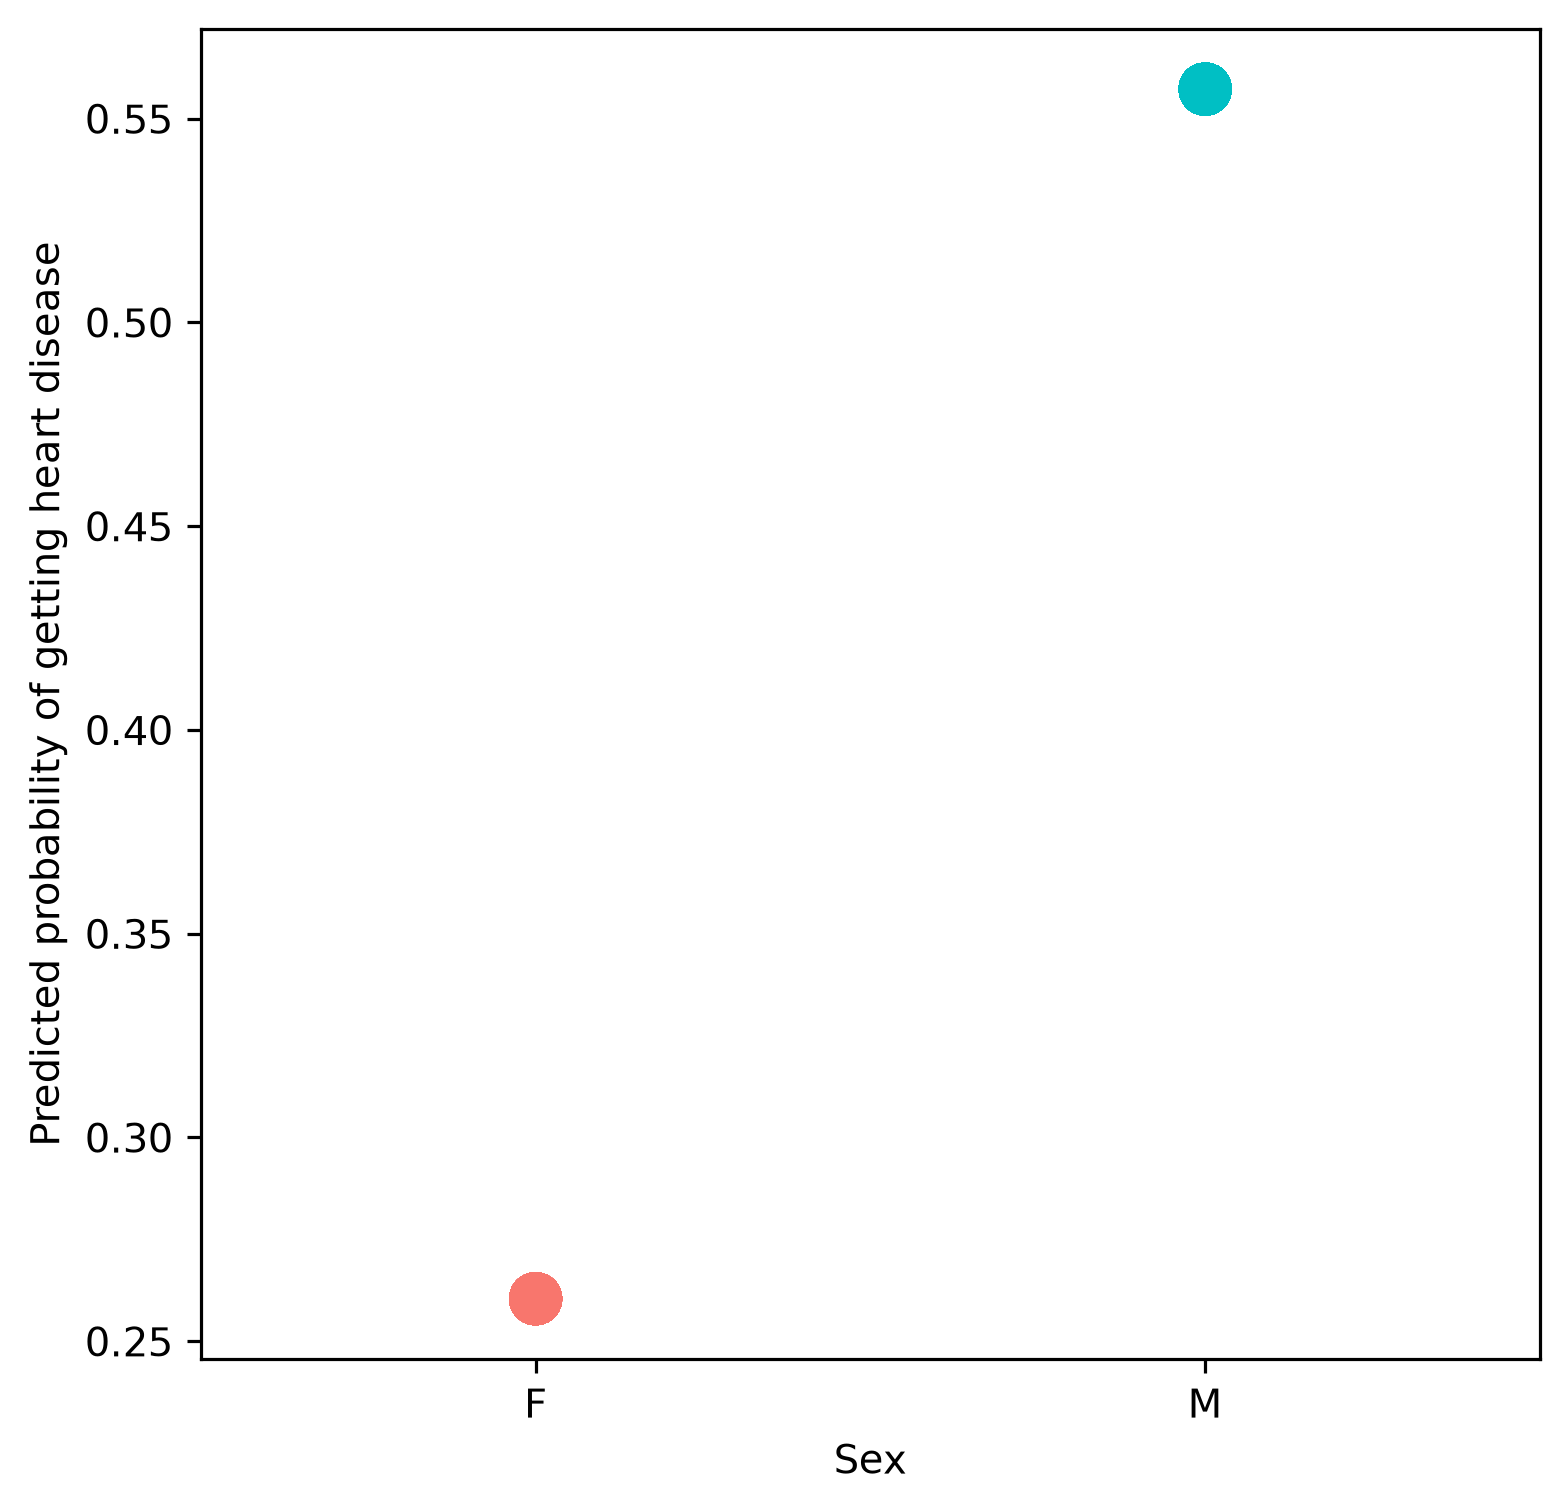

In [34]:
# plot-sex-predictions
predicted_sex = pd.DataFrame(
    {
        "probability_of_hd": logistic_sex.fittedvalues,
        "sex": df["sex"],
    }
)

sex_colors = {"F": "#F8766D", "M": "#00BFC4"}

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(
    x=predicted_sex["sex"].map({"F": 1, "M": 2}).astype(int),
    y=predicted_sex["probability_of_hd"],
    c=predicted_sex["sex"].map(sex_colors).astype(str),
    s=150,
)
ax.set_xticks([1, 2], ["F", "M"])
ax.set_xlim(0.5, 2.5)
ax.set_xlabel("Sex")
ax.set_ylabel("Predicted probability of getting heart disease")
plt.show()

# To save a PDF of the graph with a transparent background, uncomment:
# fig.savefig("single_variable_logistic_py.pdf", transparent=True, bbox_inches="tight")

The model only predicts two probabilities, one for females and one for males, so a table summarizes them too.

In [35]:
# table-sex-predictions
pd.crosstab(predicted_sex["probability_of_hd"], predicted_sex["sex"])

sex,F,M
probability_of_hd,,
0.260417,96,0
0.557214,0,201


## Full logistic regression: all variables

Now we use all of the available variables to predict heart disease. In R, `hd ~ .` means "use all of the other columns." The `statsmodels` formula interface has no `.` shortcut, so we build the formula ourselves.

In [36]:
# fit-full-model
predictors = [col for col in df.columns if col != "hd"]
formula = "hd ~ " + " + ".join(predictors)
print(formula)

logistic = smf.glm(
    formula,
    data=df,
    family=sm.families.Binomial(),
).fit()
print(logistic.summary())

hd ~ age + sex + cp + trestbps + chol + fbs + thalach + exang + oldpeak + slope + ca + thal
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     hd   No. Observations:                  297
Model:                            GLM   Df Residuals:                      278
Model Family:                Binomial   Df Model:                           18
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -92.353
Date:                Wed, 04 Nov 2026   Deviance:                       184.71
Time:                        10:54:10   Pearson chi2:                     396.
No. Iterations:                     6   Pseudo R-squ. (CS):             0.5316
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------

### McFadden's pseudo R-squared and its p-value

This is the same calculation as before. The degrees of freedom are now the number of coefficients in the full model minus 1 (for the intercept-only null model).

In [37]:
# pseudo-r2-full
ll_null = logistic.null_deviance / -2
ll_proposed = logistic.deviance / -2

pseudo_r2 = (ll_null - ll_proposed) / ll_null
p_value = chi2.sf(2 * (ll_proposed - ll_null), df=len(logistic.params) - 1)

print("McFadden's pseudo R-squared:", pseudo_r2)
print("p-value:", p_value)

McFadden's pseudo R-squared: 0.5494406321380128
p-value: 8.483873892488527e-38


### Plot the predicted probabilities

Sort the patients by their predicted probability of heart disease and plot them in rank order, colored by whether they actually had heart disease. If the model is doing a good job, most healthy patients should be on the left (low probability) and most unhealthy patients on the right (high probability).

In [38]:
# rank-predictions
predicted_data = (
    pd.DataFrame(
        {
            "probability_of_hd": logistic.fittedvalues,
            "hd": df["hd"],
        }
    )
    .sort_values("probability_of_hd")
    .assign(rank=lambda d: np.arange(1, len(d) + 1))
)

predicted_data.head()

,probability_of_hd,hd,rank
222,0.001208,0,1
221,0.002380,0,2
63,0.003310,0,3
210,0.003434,0,4
94,0.003560,0,5


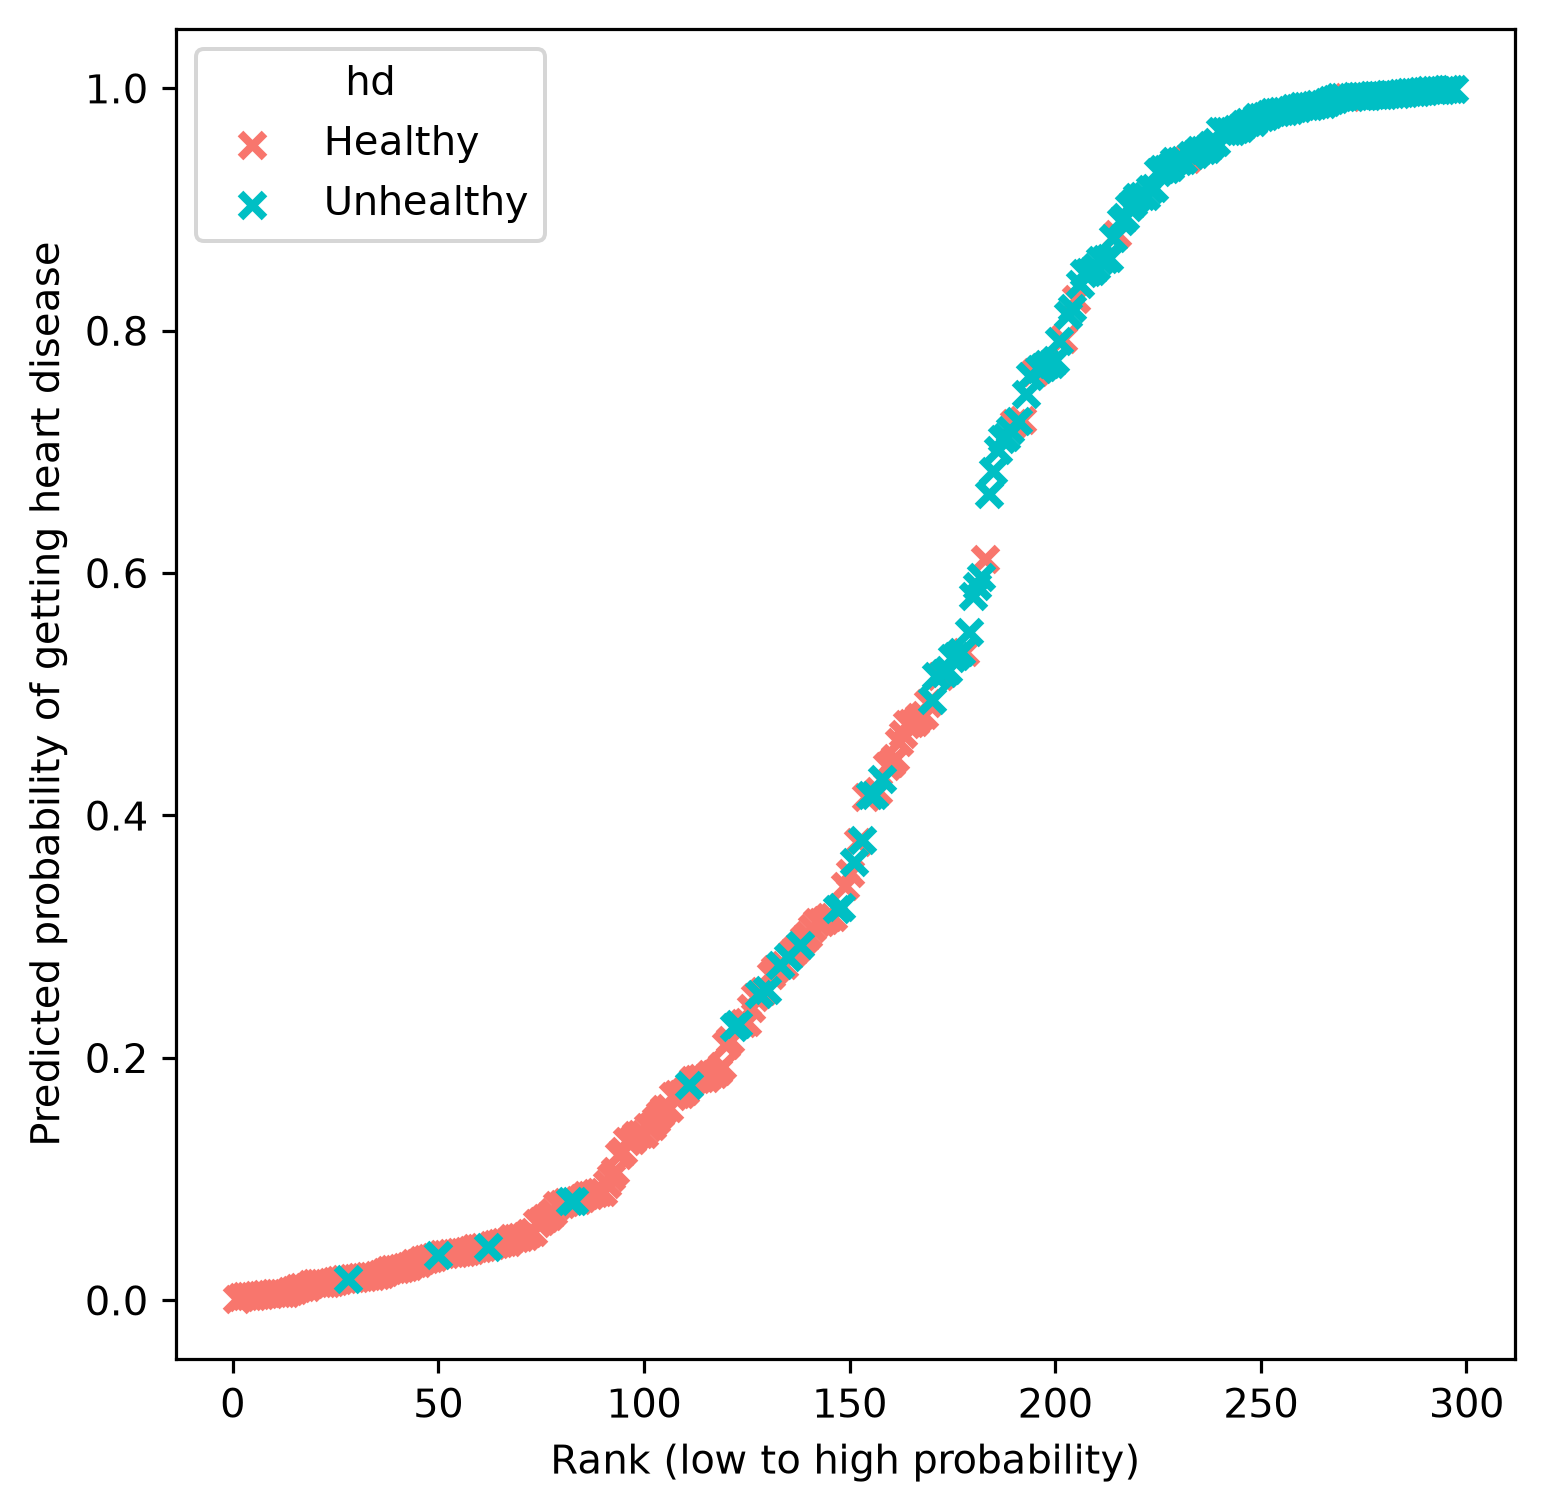

In [39]:
# plot-full-predictions
# hd is coded 0 = Healthy, 1 = Unhealthy
hd_colors = {0: "#F8766D", 1: "#00BFC4"}
hd_labels = {0: "Healthy", 1: "Unhealthy"}

fig, ax = plt.subplots(figsize=(6, 6))
for code, color in hd_colors.items():
    subset = predicted_data[predicted_data["hd"] == code]
    ax.scatter(
        subset["rank"],
        subset["probability_of_hd"],
        c=color,
        marker="x",
        linewidths=2,
        label=hd_labels[code],
    )
ax.set_xlabel("Rank (low to high probability)")
ax.set_ylabel("Predicted probability of getting heart disease")
ax.legend(loc="upper left", title="hd")
plt.show()

# To save a PDF of the graph with a transparent background, uncomment:
# fig.savefig("full_model_logistic_py.pdf", transparent=True, bbox_inches="tight")

## Make predictions for new patients

Now use the full model to predict the probability that two new (made-up) patients have heart disease. The new data must have the same columns as the data used to fit the model (except `hd`, which is what we are predicting). Each categorical column must also use the same levels as the training data, so we set `categories=df[col].cat.categories`.

`predict()` on a logistic GLM returns probabilities, not log(odds).

In [40]:
# predict-new-patients
new_patients = pd.DataFrame(
    {
        "age": [58, 35],
        "sex": ["M", "F"],
        "cp": ["4", "3"],
        "trestbps": [140, 115],
        "chol": [250, 190],
        "fbs": ["0", "0"],
        "thalach": [130, 175],
        "exang": ["1", "0"],
        "oldpeak": [1.5, 0],
        "slope": ["2", "1"],
        "ca": ["1", "0"],
        "thal": ["7", "3"],
    }
)

for col in ["sex", "cp", "fbs", "exang", "slope", "ca", "thal"]:
    new_patients[col] = pd.Categorical(
        new_patients[col],
        categories=df[col].cat.categories,
    )

new_patients["probability_of_hd"] = logistic.predict(new_patients)
new_patients[["age", "sex", "cp", "probability_of_hd"]]

,age,sex,cp,probability_of_hd
0,58,M,4,0.995334
1,35,F,3,0.002467
